# 01 · Regional dashboard

**Question it answers:** what do we know about each region right now, and how fresh is it?

The dashboard is deliberately built from the same tables the models use, so what a
farmer or officer sees is what the model sees. Two things matter more than the
numbers themselves:

1. **Freshness.** A value that is 40 days old is not the same as a value from today.
   Every satellite product here has a publishing lag — GPM's Final Run lags months,
   GRACE lags one to two months, SMAP retrieves on roughly 3 days in 5.
2. **Coverage.** Reporting a mean without saying what fraction of days had an
   observation is how dashboards end up lying quietly.

Outputs: `dashboard_status.csv`, four seasonal heatmaps.

In [1]:
# --- shared setup -----------------------------------------------------------
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

DATA = Path(os.environ.get("BH6_DATA", r"C:\Users\muhai\Desktop\BIG hero 6\Data"))
MR = DATA / "model_ready"
OUT = Path(os.environ.get("BH6_OUT", str(Path.cwd() / "outputs")))
OUT.mkdir(parents=True, exist_ok=True)

regions = ["Northwest_Rajshahi", "North_Rangpur", "Central_Dhaka", "Northeast_Sylhet",
           "Southwest_Khulna", "South_Barishal", "Southeast_Chattogram"]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e4e3de"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "font.family": "DejaVu Sans", "font.size": 9, "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 10, "axes.titlecolor": INK, "axes.spines.top": False,
    "axes.spines.right": False, "grid.color": GRID, "grid.linewidth": 0.8,
})
SEQ = LinearSegmentedColormap.from_list("brand_blue", ["#eaf2fc", "#9cc3ef", "#2a78d6", "#12365f"])

def pretty(region):
    return region.replace("_", " ")

def load_daily():
    df = pd.read_csv(MR / "daily_panel.csv", parse_dates=["date"])
    return df.sort_values(["region", "date"]).reset_index(drop=True)

def load_monthly():
    df = pd.read_csv(MR / "monthly_panel.csv", parse_dates=["date"])
    return df.sort_values(["region", "date"]).reset_index(drop=True)

def split_by_date(dates, train_end="2024-12-31", valid_end="2025-12-31"):
    d = pd.to_datetime(dates)
    return (d <= train_end), (d > train_end) & (d <= valid_end), d > valid_end

def metrics(y_true, y_pred):
    from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    ok = np.isfinite(y_true) & np.isfinite(y_pred)
    if ok.sum() < 5:
        return {"n": int(ok.sum())}
    return {"n": int(ok.sum()),
            "MAE": round(float(mean_absolute_error(y_true[ok], y_pred[ok])), 3),
            "RMSE": round(float(np.sqrt(mean_squared_error(y_true[ok], y_pred[ok]))), 3),
            "R2": round(float(r2_score(y_true[ok], y_pred[ok])), 3)}

print(f"pandas {pd.__version__} | data: {DATA}")


pandas 3.1.1 | data: C:\Users\muhai\Desktop\BIG hero 6\Data


## 1. Load the panels

`daily_panel.csv` has one row per region-day with every feature known at the end of
that day. `monthly_panel.csv` aggregates the same data per calendar month.

In [2]:
daily = load_daily()
monthly = load_monthly()
print("daily  ", daily.shape, daily["date"].min().date(), "->", daily["date"].max().date())
print("monthly", monthly.shape, monthly["date"].min().date(), "->", monthly["date"].max().date())
daily.head(3)

daily   (12313, 66) 2022-01-01 -> 2026-10-25
monthly (406, 37) 2022-01-01 -> 2026-10-01


,region,date,t2m_c,tmax_c,tmin_c,power_rain_mm,rh_pct,wind_ms,solar_mj_m2,pressure_kpa,...,sm_anomaly_30d,doy_sin,doy_cos,month,is_monsoon,season,target_rain_next_day_mm,target_sm_next_day,target_et0_next_day_mm,target_heat_next_day
0,Central_Dhaka,2022-01-01,16.96,24.09,11.35,0.0,81.15,1.53,14.63,101.70,...,NaN,0.017202,0.999852,1,0,boro,0.0,0.347877,1.804622,0.0
1,Central_Dhaka,2022-01-02,17.11,23.37,11.22,0.0,81.11,1.39,10.64,101.56,...,NaN,0.034398,0.999408,1,0,boro,0.0,NaN,2.065970,0.0
2,Central_Dhaka,2022-01-03,16.98,23.21,11.45,0.0,81.81,1.38,14.08,101.50,...,NaN,0.051584,0.998669,1,0,boro,0.0,0.394098,2.086360,0.0


## 2. Freshness and coverage per variable

For each region and each source we ask: when was the last observation, how old is it,
and what share of the last 30 days carried a value? The `*_observed_today` and
`*_age_days` columns exist precisely for this.

In [3]:
SOURCES = {
    "rainfall (GPM)": "gpm_rain_mm",
    "soil moisture (SMAP)": "sm_mean",
    "vegetation (HLS NDVI)": "ndvi_last",
    "surface temp (ECOSTRESS)": "lst_c_last",
    "water storage (GRACE)": "grace_lwe_cm_last",
    "weather (POWER)": "t2m_c",
}

last_date = daily["date"].max()
recent = daily[daily["date"] > last_date - pd.Timedelta(days=30)]

rows = []
for region, g in daily.groupby("region"):
    rec = {"region": pretty(region)}
    for label, col in SOURCES.items():
        s = g[col].dropna()
        last = g.loc[g[col].notna(), "date"].max() if len(s) else pd.NaT
        rec[f"{label} · last"] = last.date().isoformat() if pd.notna(last) else "never"
        rec[f"{label} · age d"] = int((last_date - last).days) if pd.notna(last) else None
        gr = recent[recent["region"] == region]
        rec[f"{label} · 30d %"] = round(100 * gr[col].notna().mean(), 0) if len(gr) else np.nan
    rows.append(rec)

fresh = pd.DataFrame(rows)
fresh.to_csv(OUT / "dashboard_status.csv", index=False)
fresh.iloc[:, :7].set_index("region")

,rainfall (GPM) · last,rainfall (GPM) · age d,rainfall (GPM) · 30d %,soil moisture (SMAP) · last,soil moisture (SMAP) · age d,soil moisture (SMAP) · 30d %
region,,,,,,
Central Dhaka,2026-10-25,0,100.0,2026-10-25,0,60.0
North Rangpur,2026-10-25,0,100.0,2026-10-25,0,67.0
Northeast Sylhet,2026-10-25,0,100.0,2026-10-25,0,60.0
Northwest Rajshahi,2026-10-25,0,100.0,2026-10-25,0,67.0
South Barishal,2026-10-25,0,100.0,2026-10-25,0,67.0
Southeast Chattogram,2026-10-25,0,100.0,2026-10-25,0,57.0
Southwest Khulna,2026-10-25,0,100.0,2026-10-25,0,67.0


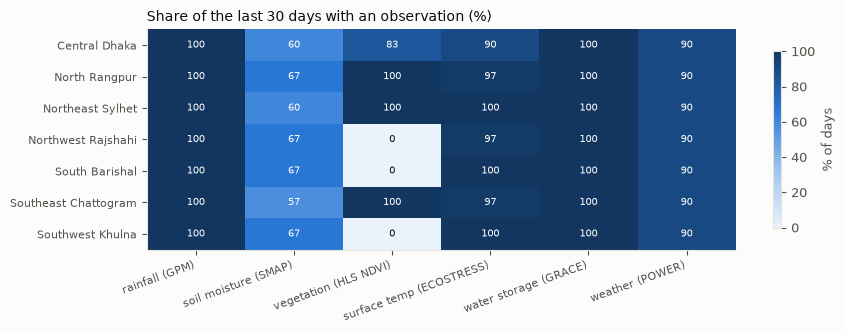

In [4]:
coverage = fresh.set_index("region")[[c for c in fresh.columns if c.endswith("30d %")]]
fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(coverage.values, cmap=SEQ, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(coverage.columns)))
ax.set_xticklabels([c.replace(" · 30d %", "") for c in coverage.columns], rotation=20, ha="right", fontsize=8)
ax.set_yticks(range(len(coverage.index)))
ax.set_yticklabels(coverage.index, fontsize=8)
for i in range(coverage.shape[0]):
    for j in range(coverage.shape[1]):
        v = coverage.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if v > 55 else INK)
ax.set_title("Share of the last 30 days with an observation (%)", loc="left")
fig.colorbar(im, ax=ax, shrink=0.8, label="% of days")
fig.tight_layout()
plt.show()

## 3. Seasonal fingerprints

A single "current value" is meaningless without its season. These heatmaps show each
region's normal month — the context a dashboard needs behind today's number.

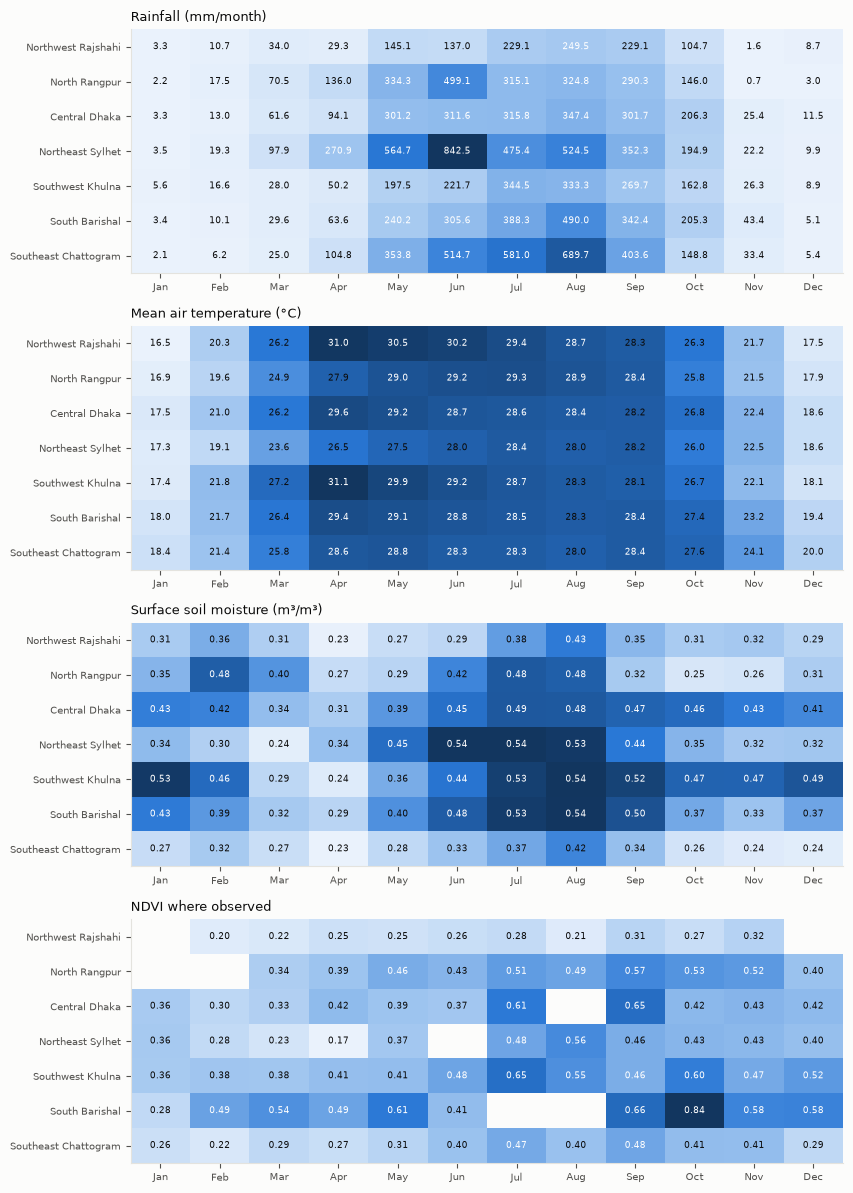

In [5]:
def seasonal_heat(ax, frame, column, title, fmt="{:.1f}", cmap=SEQ):
    pivot = frame.pivot_table(index="region", columns=frame["date"].dt.month, values=column, aggfunc="mean")
    pivot = pivot.reindex(index=regions, columns=range(1, 13))
    im = ax.imshow(pivot.values, cmap=cmap, aspect="auto")
    ax.set_xticks(range(12)); ax.set_xticklabels(months, fontsize=7)
    ax.set_yticks(range(len(regions))); ax.set_yticklabels([pretty(r) for r in regions], fontsize=7)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            v = pivot.values[i, j]
            if np.isfinite(v):
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=6.5,
                        color="white" if v > np.nanpercentile(pivot.values, 65) else INK)
    ax.set_title(title, loc="left", fontsize=9)
    return im

fig, axes = plt.subplots(4, 1, figsize=(8.6, 12))
seasonal_heat(axes[0], monthly, "rain_mm", "Rainfall (mm/month)")
seasonal_heat(axes[1], monthly, "t2m_c", "Mean air temperature (°C)")
seasonal_heat(axes[2], monthly, "sm_mean", "Surface soil moisture (m³/m³)", "{:.2f}")
seasonal_heat(axes[3], monthly, "ndvi", "NDVI where observed", "{:.2f}")
fig.tight_layout()
plt.show()

## 4. Current status

For each region: rainfall over the last 30 days, how it compares with the same window
in previous years, the latest soil-moisture percentile, and the freshest NDVI.

The comparison uses the *same calendar window* in earlier years, not the annual mean —
comparing a January against an annual average would manufacture a drought every winter.

In [6]:
cut = last_date - pd.Timedelta(days=30)
rows = []
for region, g in daily.groupby("region"):
    g = g.set_index("date")
    window = g.loc[g.index > cut]
    rain_30 = window["gpm_rain_mm"].sum(min_count=1)

    same_windows = []
    for year in (2022, 2023, 2024, 2025):
        start, end = cut.replace(year=year), last_date.replace(year=year)
        w = g.loc[(g.index > start) & (g.index <= end), "gpm_rain_mm"]
        if w.notna().any():
            same_windows.append(w.sum())
    clim = float(np.mean(same_windows)) if same_windows else np.nan

    sm = g["sm_mean"].dropna()
    sm_pct = float((sm < sm.iloc[-1]).mean() * 100) if len(sm) and np.isfinite(sm.iloc[-1]) else np.nan

    ndvi = g["ndvi_last"].dropna()
    rows.append({
        "region": pretty(region),
        "rain 30d mm": round(float(rain_30), 1) if np.isfinite(rain_30) else None,
        "same window avg mm": round(clim, 1) if np.isfinite(clim) else None,
        "anomaly %": round(100 * (rain_30 - clim) / clim, 0) if np.isfinite(clim) and clim > 0 else None,
        "soil moisture pct": round(sm_pct, 0) if np.isfinite(sm_pct) else None,
        "NDVI latest": round(float(ndvi.iloc[-1]), 2) if len(ndvi) else None,
        "NDVI age d": int((last_date - g.index[g["ndvi_last"].notna()][-1]).days) if len(ndvi) else None,
    })
status = pd.DataFrame(rows)
status.to_csv(OUT / "current_status.csv", index=False)
status

,region,rain 30d mm,same window avg mm,anomaly %,soil moisture pct,NDVI latest,NDVI age d
0,Central Dhaka,78.8,282.2,-72.0,41.0,0.34,0
1,North Rangpur,32.4,201.6,-84.0,1.0,0.50,0
2,Northeast Sylhet,51.9,273.9,-81.0,43.0,0.32,0
3,Northwest Rajshahi,17.1,140.3,-88.0,23.0,0.41,68
4,South Barishal,9.7,268.6,-96.0,15.0,0.64,299
5,Southeast Chattogram,101.6,213.7,-52.0,6.0,0.30,0
6,Southwest Khulna,8.6,219.8,-96.0,44.0,0.64,68


## 5. Reading this honestly

- **`anomaly %` needs a wet season to mean anything.** In January a "−100%" anomaly may
  be 3 mm versus 6 mm. Read it beside the absolute totals, never alone.
- **`NDVI age d` is often 20–45 days.** HLS only sees through cloud; in the monsoon an
  apparently stale NDVI is the normal state, not a fault.
- **Percentiles are computed against the whole record for that region**, so a value in
  the 10th percentile is dry *for that region*, not dry in absolute terms.
- GRACE and soil moisture are regional context. Neither is a field measurement, and
  neither should drive an irrigation decision on its own.